# Simplified EDA: Predicting Machine Maintenance

**Goal of the project:** build an alert system that tells the maintenance team when a machine needs maintenance, so that machines do not break down unexpectedly.

**Target column:** `maintenance_required` (0 = no, 1 = yes)

**What this notebook does:** this is the EDA (Task 1). We explore and clean the data to understand it. No models are trained here; that is done in the pipeline (Task 2).

Each section explains **why** we do the step, shows the code, and ends with **what we found**.

### Contents
1. Loading the data
2. Target column
3. Sensor columns
4. Derived columns
5. Cleaning the data
6. How the target is made
7. Sensors vs target
8. Machine and time
9. Decisions
10. Summary

### Main findings
- The data is clean overall: 100,000 rows, no duplicates, and one reading every minute from a random machine.
- 19.7 % of readings need maintenance, so accuracy alone would be misleading.
- `temperature` is missing in 14 % of rows. We fill these with the median and add a "missing" column.
- 6.7 % of `vibration` values are negative. They are real values with a wrong minus sign, so we use the absolute value.
- `maintenance_required` is made from a simple rule: **anomaly OR machine failed OR remaining life < 20 hours**. These derived columns give away the answer, so they should not be used to train models.
- Only `temperature` (above 90 °C) and `vibration` (above 80 mm/s) are linked to maintenance. Humidity, pressure, energy, machine and time are not.
- Only about 41 % of maintenance cases show up in the sensors. The rest cannot be seen in this data.

## 1. Loading the data
**Why:** before analysing anything, we check that the data loaded correctly: the column types, the missing values, any duplicates, and the time range.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

TARGET = "maintenance_required"
SENSORS = ["temperature", "vibration", "humidity", "pressure", "energy_consumption"]

df = pd.read_csv("data/proj_machine_readings.csv", parse_dates=["timestamp"])
print(df.shape)
df.head()

(100000, 13)


,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


**Why this table:** `info()` shows each column's type and how many values are filled in, so we can spot wrong types and missing data.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   timestamp                 100000 non-null  datetime64[us]
 1   machine_id                100000 non-null  int64         
 2   temperature               86000 non-null   float64       
 3   vibration                 100000 non-null  float64       
 4   humidity                  100000 non-null  float64       
 5   pressure                  100000 non-null  float64       
 6   energy_consumption        100000 non-null  float64       
 7   machine_status            100000 non-null  int64         
 8   anomaly_flag              100000 non-null  int64         
 9   predicted_remaining_life  100000 non-null  int64         
 10  failure_type              100000 non-null  str           
 11  downtime_risk             100000 non-null  float64       
 12  maintenance_re

In [3]:
print("Duplicate rows:", df.duplicated().sum())
print("Time range:", df["timestamp"].min(), "to", df["timestamp"].max())
print("Every row exactly 1 minute after the previous one:", (df["timestamp"].diff().dropna() == pd.Timedelta("1min")).all())
print("Number of machines:", df["machine_id"].nunique())
print("Readings per machine:", df["machine_id"].value_counts().min(), "to", df["machine_id"].value_counts().max())

Duplicate rows: 0
Time range: 2025-01-01 00:00:00 to 2025-03-11 10:39:00
Every row exactly 1 minute after the previous one: True
Number of machines: 50
Readings per machine: 1906 to 2092


**What we found**
- 100,000 rows and 13 columns. All types are correct: numbers are numbers, and `timestamp` is a date.
- Only `temperature` has missing values (14,000 rows).
- There are no duplicate rows.
- There is exactly **one reading per minute**, from 1 Jan to 11 Mar 2025. Each minute, one of the 50 machines sends a reading, and each machine has about 2,000 readings.
- `machine_id`, `machine_status`, `anomaly_flag` and `maintenance_required` are stored as numbers, but they are really **categories** (labels), not amounts.

## 2. Target column: `maintenance_required`
**Why:** we need to know how many readings need maintenance. If one class is much bigger, some ways of measuring a model can be misleading.

maintenance_required
0    80303
1    19697
Name: count, dtype: int64
maintenance_required
0    80.3
1    19.7
Name: count, dtype: float64


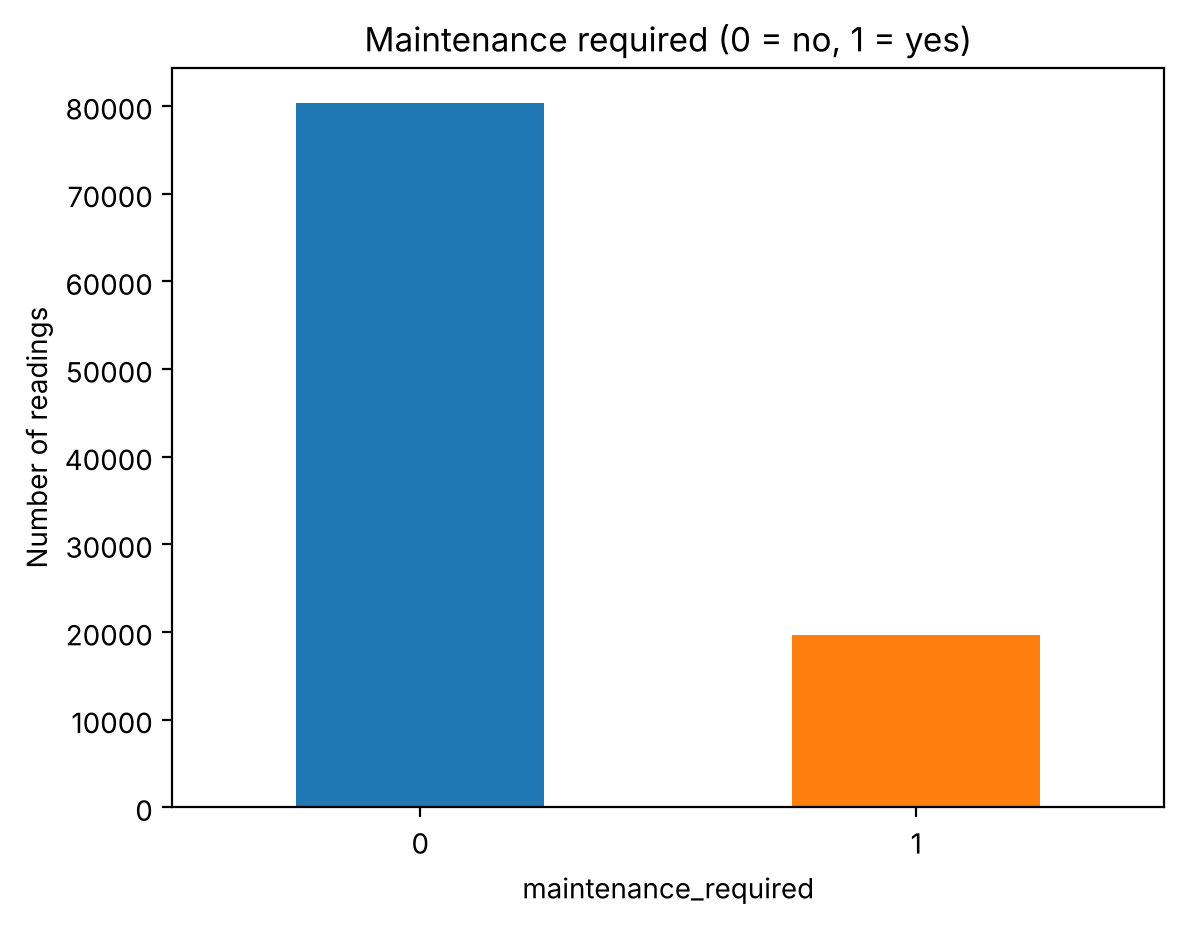

In [4]:
counts = df[TARGET].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))

counts.plot(kind="bar", color=["tab:blue", "tab:orange"], title="Maintenance required (0 = no, 1 = yes)")
plt.ylabel("Number of readings")
plt.xticks(rotation=0)
plt.show()

**What we found**
- 19.7 % of readings need maintenance and 80.3 % do not.
- A model that **always says "no maintenance" would already be 80 % accurate**, but it would miss every machine that needs help. So accuracy alone is not a good measure here.
- Missing a machine that needs maintenance (a breakdown) is worse than a false alarm (an extra check). Task 2 should therefore focus on **recall**: how many real maintenance cases we catch.

## 3. Sensor columns
**Why this table:** `describe()` gives the minimum, maximum, average and spread of each sensor, so we can spot impossible values and outliers.

In [5]:
df[SENSORS].describe().round(2)

,temperature,vibration,humidity,pressure,energy_consumption
count,86000.00,100000.00,100000.00,100000.00,100000.00
mean,75.03,43.32,55.00,3.00,2.75
std,10.04,29.13,14.44,1.15,1.30
min,35.55,-106.98,30.00,1.00,0.50
25%,68.28,37.22,42.52,2.00,1.63
50%,75.09,48.64,54.98,3.01,2.74
75%,81.78,59.25,67.50,4.00,3.87
max,121.94,113.80,80.00,5.00,5.00


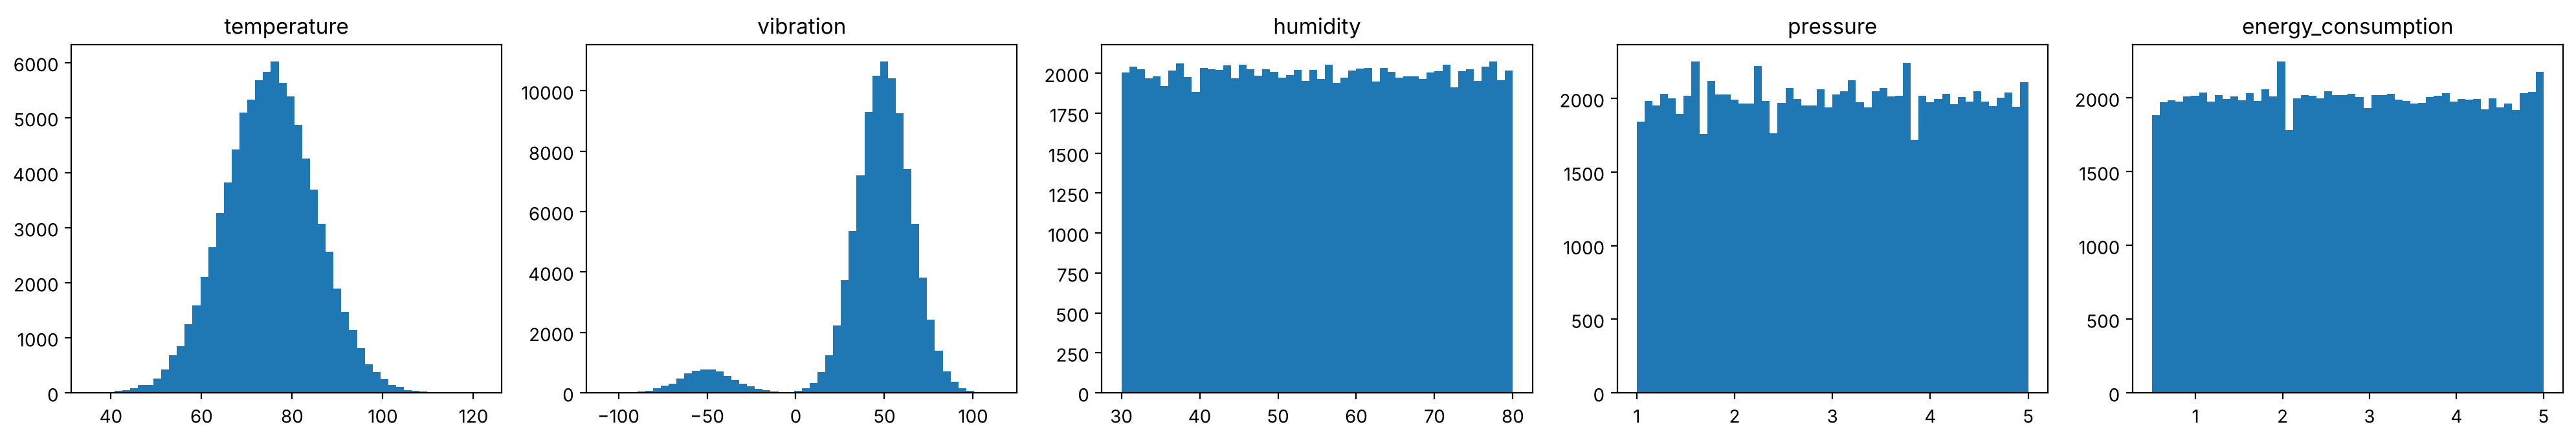

Negative vibration values: 6703 (6.7%)


In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for ax, col in zip(axes, SENSORS):
    ax.hist(df[col].dropna(), bins=50)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print("Negative vibration values:", (df["vibration"] < 0).sum(), f"({(df['vibration'] < 0).mean():.1%})")

**What we found**
- **temperature:** bell-shaped around 75 °C (from 35.6 to 121.9 °C), and 14 % missing.
- **vibration:** mostly around 50 mm/s, but **6,703 values (6.7 %) are negative**. Vibration level cannot be below zero, so we look into this in Section 5.
- **humidity** (30 to 80 %), **pressure** (1 to 5 bar) and **energy_consumption** (0.5 to 5 kWh) are spread flat and evenly, with no outliers. Real sensors usually cluster around a normal value, so the data is probably **simulated**.

## 4. Derived columns
**Why:** the problem statement says some columns are *derived* (calculated from other data). We look at their values first, to understand them before deciding how to use them.

**Why these tables:** the value counts show how often each category appears.

In [7]:
for col in ["machine_status", "anomaly_flag", "failure_type", "downtime_risk"]:
    print(df[col].value_counts(), "\n")

machine_status
1    80091
2    10057
0     9852
Name: count, dtype: int64 

anomaly_flag
0    91084
1     8916
Name: count, dtype: int64 

failure_type
Normal              91899
Vibration Issue      3129
Overheating          1989
Pressure Drop        1969
Electrical Fault     1014
Name: count, dtype: int64 

downtime_risk
0.00    91084
1.00     8904
0.98        3
0.99        3
0.97        2
0.92        1
0.94        1
0.88        1
0.93        1
Name: count, dtype: int64 



**Why this table:** to check how `failure_type` relates to `machine_status`.

In [8]:
pd.crosstab(df["machine_status"], df["failure_type"])

failure_type,Electrical Fault,Normal,Overheating,Pressure Drop,Vibration Issue
machine_status,,,,,
0,0,9852,0,0,0
1,0,80091,0,0,0
2,1014,1956,1989,1969,3129


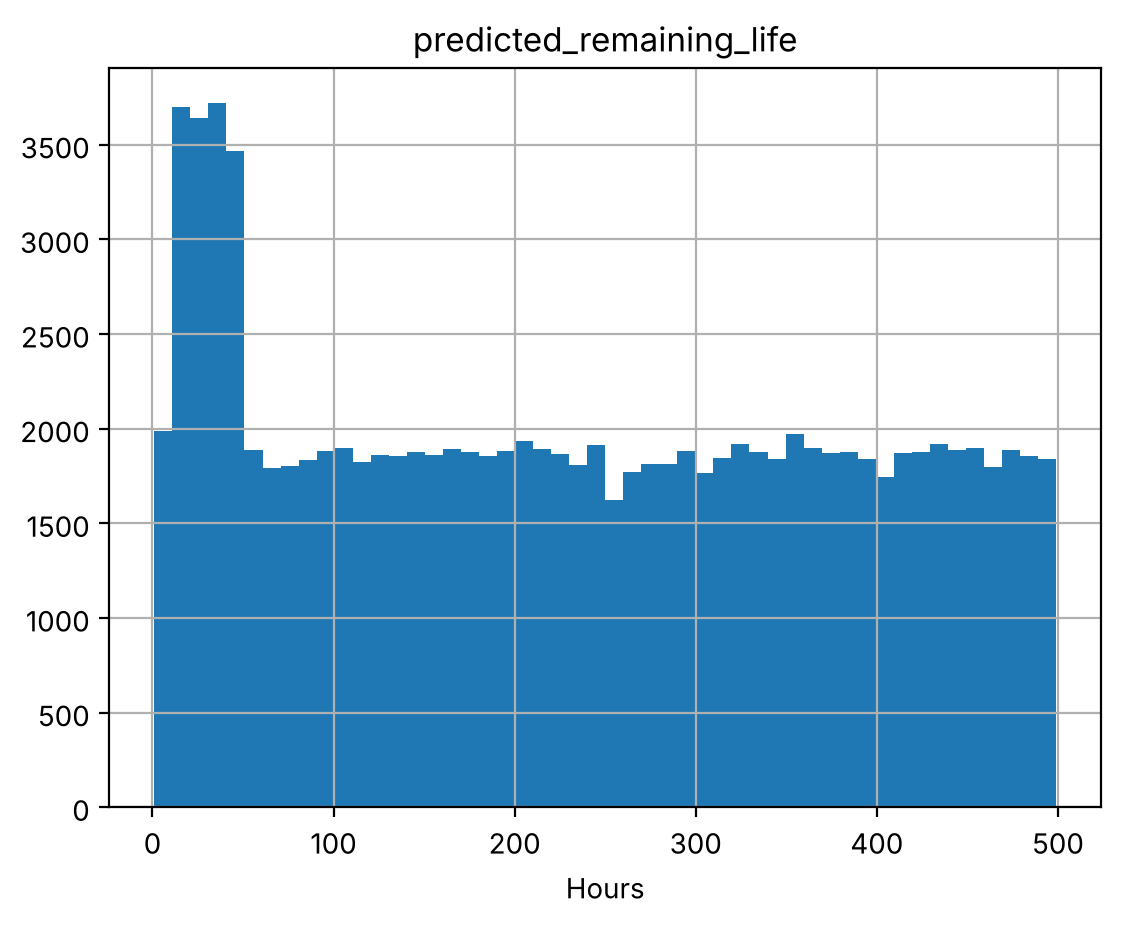

In [9]:
df["predicted_remaining_life"].hist(bins=50)
plt.title("predicted_remaining_life")
plt.xlabel("Hours")
plt.show()

**What we found**
- `machine_status`: 80 % running (1), 10 % idle (0), 10 % failed (2).
- `anomaly_flag`: 8.9 % of readings are flagged as unusual.
- `failure_type` is only filled in when the machine has failed (status 2). However, **1,956 failed readings are labelled "Normal"**, which does not make sense. We note this but do not change it, because we cannot know the correct label.
- `downtime_risk` is almost always exactly 0 or 1. Only 12 rows have values in between.
- `predicted_remaining_life` goes from 1 to 499 hours, with extra readings below 50 hours.

## 5. Cleaning the data
We work on a copy (`df_clean`), so the original data stays unchanged.

In [10]:
df_clean = df.copy()

### 5.1 Negative vibration
**Why:** negative vibration is impossible. We need to know whether these values are rubbish, or real values that got a wrong minus sign.

**Test 1:** if the minus sign is the only problem, the negative values (with the minus removed) should look the same as the positive values.

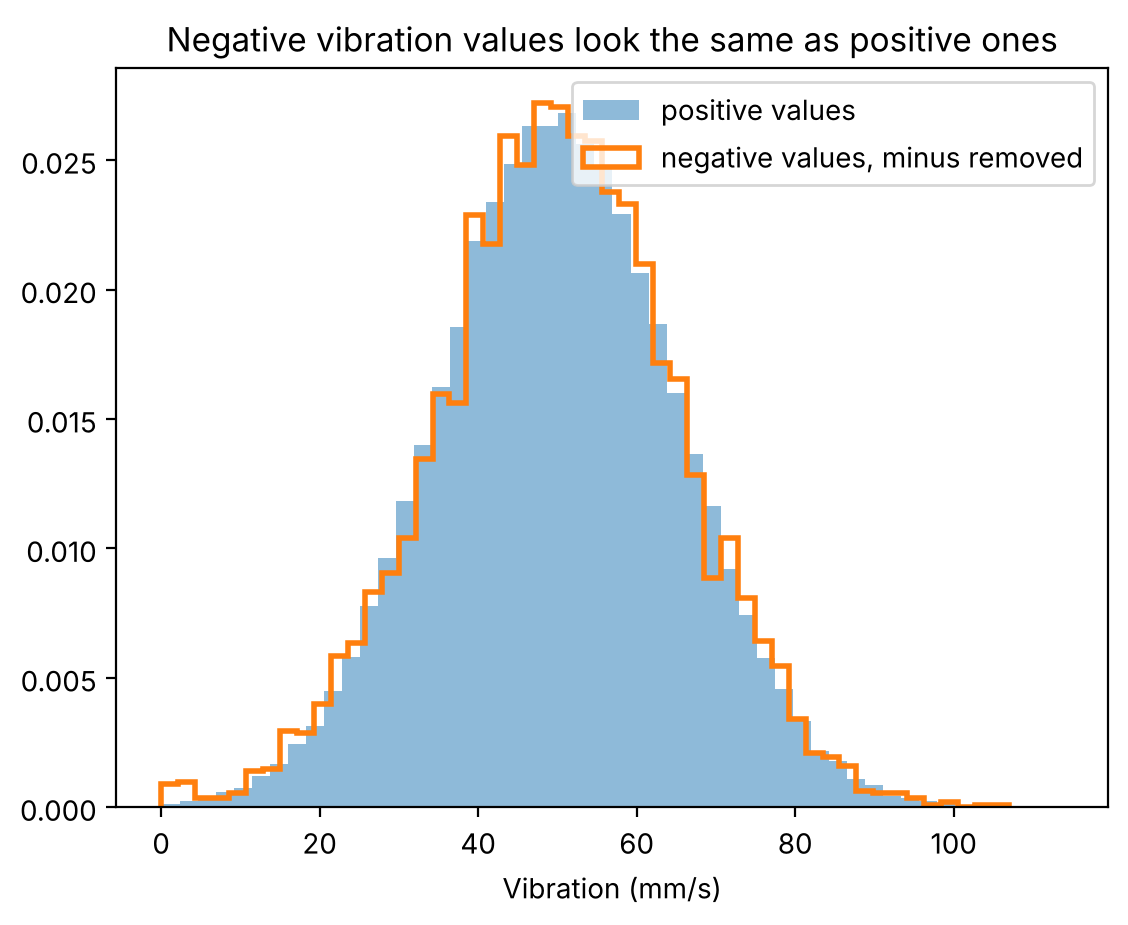

Average of positive values: 50.02
Average of negative values (minus removed): 49.91


In [11]:
positive = df.loc[df["vibration"] >= 0, "vibration"]
negative_flipped = -df.loc[df["vibration"] < 0, "vibration"]

plt.hist(positive, bins=50, density=True, alpha=0.5, label="positive values")
plt.hist(negative_flipped, bins=50, density=True, histtype="step", linewidth=2, label="negative values, minus removed")
plt.title("Negative vibration values look the same as positive ones")
plt.xlabel("Vibration (mm/s)")
plt.legend()
plt.show()

print("Average of positive values:", round(positive.mean(), 2))
print("Average of negative values (minus removed):", round(negative_flipped.mean(), 2))

**Test 2:** `anomaly_flag` marks high vibration. If the minus sign is fake, a value like -85 should still be flagged as an anomaly, as if it were +85.

**Why this table:** it compares how often each vibration group is flagged. We only use rows with a normal temperature (below 90 °C), so that the flag can only come from vibration.

In [12]:
normal_temp = df["temperature"] < 90
groups = {
    "below -80": (df["vibration"] < -80) & normal_temp,
    "-80 to 0": (df["vibration"] >= -80) & (df["vibration"] < 0) & normal_temp,
    "0 to 80": (df["vibration"] >= 0) & (df["vibration"] < 80) & normal_temp,
    "above 80": (df["vibration"] > 80) & normal_temp,
}
pd.DataFrame({
    "rows": {name: rows.sum() for name, rows in groups.items()},
    "% flagged as anomaly": {name: df.loc[rows, "anomaly_flag"].mean() * 100 for name, rows in groups.items()},
})

,rows,% flagged as anomaly
below -80,110,100.0
-80 to 0,4891,0.0
0 to 80,73413,0.0
above 80,1741,100.0


**What we found**
- The negative values (with the minus removed) have the same shape and the same average (about 50 mm/s) as the positive values.
- **Every reading below -80 is flagged as an anomaly, just like readings above +80.** So the anomaly flag was calculated using the real (positive) values.

**Decision:** the minus sign is a recording error, so we take the **absolute value** of vibration. Removing the rows would throw away 6.7 % of good data. Keeping the negatives would make -85 look like "very low vibration".

In [13]:
df_clean["vibration"] = df_clean["vibration"].abs()
print("Negative values left:", (df_clean["vibration"] < 0).sum())

Negative values left: 0


### 5.2 Missing temperature
**Why:** before filling in missing values, we check whether the missing rows are different from the others. If they are, filling them in the wrong way could hide important information.

**Why this table:** it compares rows with and without temperature on the target and on other columns.

In [14]:
missing = df_clean["temperature"].isna()
comparison = df_clean.groupby(missing)[[TARGET, "anomaly_flag"]].mean() * 100
comparison.index = ["temperature known", "temperature missing"]
comparison.round(1)

,maintenance_required,anomaly_flag
temperature known,19.7,8.9
temperature missing,19.4,8.8


**Chi-square test.** This is the one statistical test we use, here and in Section 8. It checks whether two categories are linked (here: "temperature missing?" and "needs maintenance?"). **If the p-value is above 0.05, we treat them as not linked.**

In [15]:
p_value = stats.chi2_contingency(pd.crosstab(missing, df_clean[TARGET])).pvalue
print("Chi-square p-value:", round(p_value, 2))
print("Missing % per machine:", round(missing.groupby(df_clean["machine_id"]).mean().min() * 100, 1),
      "to", round(missing.groupby(df_clean["machine_id"]).mean().max() * 100, 1))

Chi-square p-value: 0.31
Missing % per machine: 12.6 to 15.7


**What we found:** the missing rows have about the same maintenance rate (19.4 % vs 19.7 %) and anomaly rate (8.8 % vs 8.9 %) as the other rows, and p = 0.31, so they are **not linked**. Every machine has between 12.6 % and 15.7 % missing. The values are missing at random.

**Choosing how to fill them in**

**Why this table:** to choose between the mean and the median, and to check whether other sensors could help predict the missing temperature.

In [16]:
print("Mean temperature:  ", round(df_clean["temperature"].mean(), 2))
print("Median temperature:", round(df_clean["temperature"].median(), 2))
print()
print("Correlation of temperature with the other sensors:")
print(df_clean[SENSORS].corr()["temperature"].round(3))

Mean temperature:   75.03
Median temperature: 75.09

Correlation of temperature with the other sensors:
temperature           1.000
vibration            -0.003
humidity              0.003
pressure             -0.001
energy_consumption    0.004
Name: temperature, dtype: float64


- The mean and median are almost the same (75.0 °C). We use the **median**, because extreme values affect it less.
- Temperature has **no correlation** with any other sensor. Methods that predict missing values from other columns (such as KNN) would therefore not do better than the median.
- We do not fill the gaps per machine either, because machines do not differ from each other (Section 8).

**One problem with filling in the median:** the chart below shows that rows with missing temperature need maintenance more often (19.4 %) than normal rows near 75 °C (13.8 %). This is because some of the missing values were really high temperatures. If we just put in 75 °C, those rows would look safer than they are.

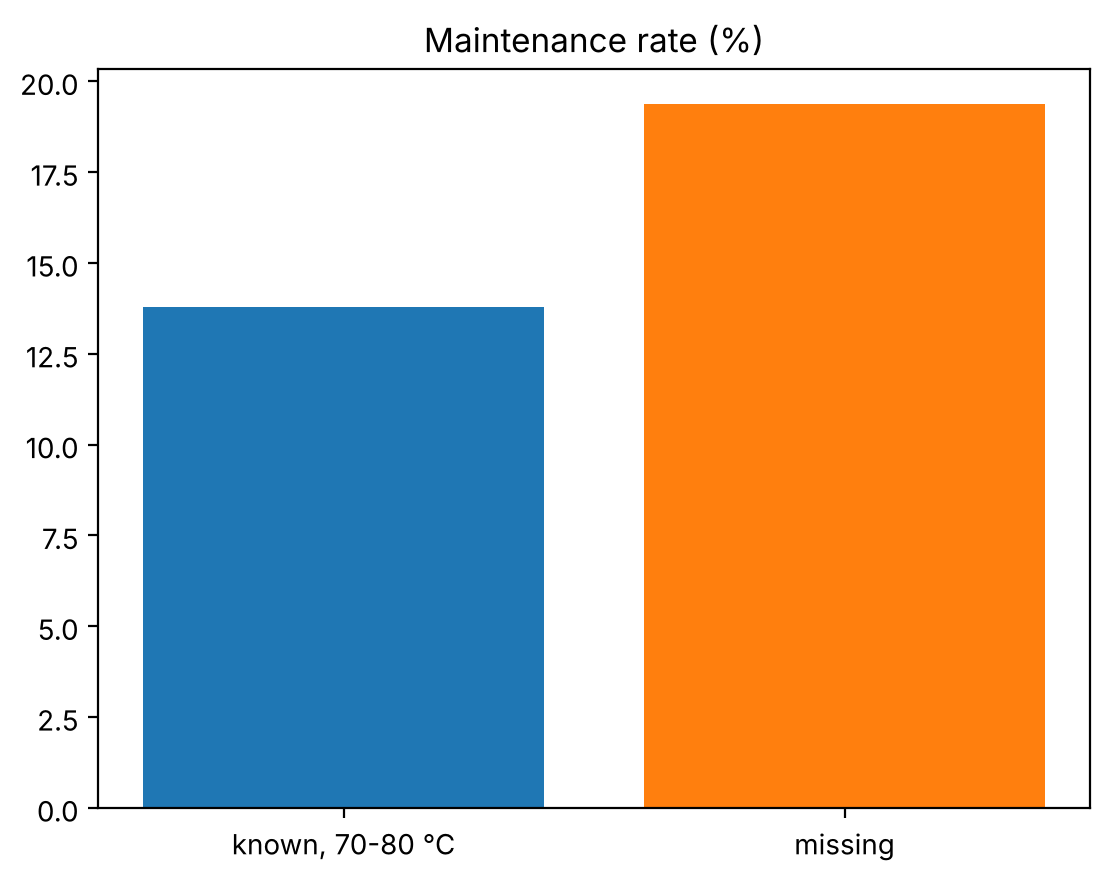

known, 70-80 °C: 13.8 %
missing: 19.4 %


In [17]:
rates = {
    "known, 70-80 °C": df_clean.loc[df_clean["temperature"].between(70, 80), TARGET].mean() * 100,
    "missing": df_clean.loc[missing, TARGET].mean() * 100,
}
plt.bar(rates.keys(), rates.values(), color=["tab:blue", "tab:orange"])
plt.title("Maintenance rate (%)")
plt.show()
for name, value in rates.items():
    print(f"{name}: {value:.1f} %")

**Decision:** fill missing temperatures with the **median**, and add a column **`temperature_missing`** (1 = was missing). This column lets a model learn that missing rows are riskier.

**Important for Task 2:** the median must be calculated from the **training data only**, then used on the test data. Here we use the whole dataset only for exploring.

In [18]:
df_clean["temperature_missing"] = missing.astype(int)
df_clean["temperature_filled"] = df_clean["temperature"].fillna(df_clean["temperature"].median())
df_clean[["temperature", "temperature_filled", "temperature_missing"]].describe().round(2)

,temperature,temperature_filled,temperature_missing
count,86000.00,100000.00,100000.00
mean,75.03,75.04,0.14
std,10.04,9.31,0.35
min,35.55,35.55,0.00
25%,68.28,69.50,0.00
50%,75.09,75.09,0.00
75%,81.78,80.58,0.00
max,121.94,121.94,1.00


### 5.3 Outliers
**Why:** we check whether the extreme temperatures are errors to remove, or real values to keep.

**Why this table:** it counts the outliers (using the 1.5 x IQR rule) and shows how often they need maintenance.

In [19]:
q1, q3 = df_clean["temperature"].quantile([0.25, 0.75])
low_limit, high_limit = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
temp = df_clean["temperature"]

pd.DataFrame({
    "rows": [(temp < low_limit).sum(), (temp > high_limit).sum()],
    "% needing maintenance": [df_clean.loc[temp < low_limit, TARGET].mean() * 100,
                              df_clean.loc[temp > high_limit, TARGET].mean() * 100],
}, index=[f"below {low_limit:.1f} °C", f"above {high_limit:.1f} °C"]).round(1)

,rows,% needing maintenance
below 48.0 °C,351,15.1
above 102.0 °C,298,100.0


**What we found:** the high outliers **all need maintenance**. They are the most useful readings in the dataset, not mistakes. The low outliers are just the normal tail of a bell-shaped curve.

**Decision:** keep all outliers. Removing them would remove the pattern we want the model to learn.

### 5.4 Other issues (not changed)
- **1,956 failed machines labelled "Normal"** in `failure_type`: kept as-is, since we cannot know the correct label.
- **12 `downtime_risk` values between 0 and 1**: kept as-is.

Neither column will be used for training (Section 6), so these issues do not affect the models.

## 6. How the target is made
**Why:** the problem statement asks which features decide `maintenance_required`. Some columns are derived, so we check whether the target is calculated from them. If it is, using those columns in a model would be **cheating (data leakage)**: the model would look perfect but would not work in real life.

### Step 1: which conditions always lead to maintenance?
**Why this table:** for each derived column, it shows the maintenance rate when a "warning" condition is true. 100 % means "always maintenance".

In [20]:
conditions = {
    "anomaly_flag = 1": df_clean["anomaly_flag"] == 1,
    "downtime_risk > 0": df_clean["downtime_risk"] > 0,
    "machine_status = 2 (failed)": df_clean["machine_status"] == 2,
    "failure_type is not Normal": df_clean["failure_type"] != "Normal",
    "remaining life < 50 hours": df_clean["predicted_remaining_life"] < 50,
}
pd.DataFrame({
    "rows": {name: rows.sum() for name, rows in conditions.items()},
    "% needing maintenance": {name: df_clean.loc[rows, TARGET].mean() * 100 for name, rows in conditions.items()},
}).round(1)

,rows,% needing maintenance
anomaly_flag = 1,8916,100.0
downtime_risk > 0,8916,100.0
machine_status = 2 (failed),10057,100.0
failure_type is not Normal,8101,100.0
remaining life < 50 hours,16333,69.4


**What we found:** an anomaly, a downtime risk, a failed machine and a failure type **always** lead to maintenance. Remaining life below 50 hours does not (69 %), so the remaining-life cut-off must be lower.

### Step 2: what about the other maintenance cases?
We remove the anomaly and failed rows, then plot the maintenance rate against remaining life.

Rows left: 81951 | still needing maintenance: 1648


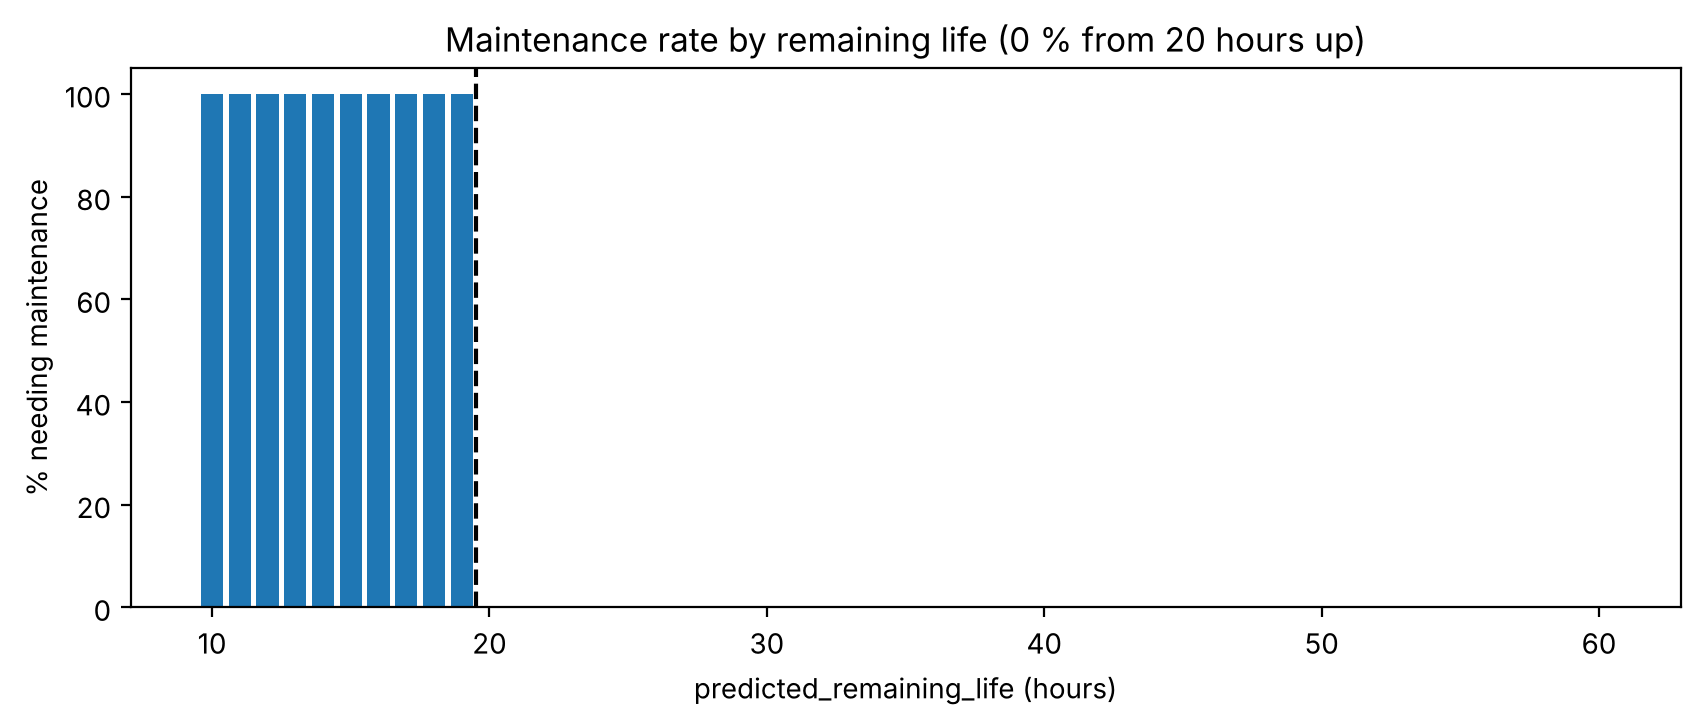

In [21]:
rest = df_clean[(df_clean["anomaly_flag"] == 0) & (df_clean["machine_status"] != 2)]
print("Rows left:", len(rest), "| still needing maintenance:", rest[TARGET].sum())

rate_by_life = rest[rest["predicted_remaining_life"] <= 60].groupby("predicted_remaining_life")[TARGET].mean() * 100
plt.figure(figsize=(10, 3.5))
plt.bar(rate_by_life.index, rate_by_life)
plt.axvline(19.5, color="black", linestyle="--")
plt.title("Maintenance rate by remaining life (0 % from 20 hours up)")
plt.xlabel("predicted_remaining_life (hours)")
plt.ylabel("% needing maintenance")
plt.show()

**What we found:** maintenance is needed **only when remaining life is below 20 hours**. The rate is 100 % below 20 hours and 0 % from 20 hours up.

### Step 3: how is `anomaly_flag` made?
We look for the highest sensor values that are **not** flagged.

In [22]:
not_flagged = df_clean[df_clean["anomaly_flag"] == 0]
print("Highest temperature that is NOT an anomaly:", not_flagged["temperature"].max())
print("Highest vibration that is NOT an anomaly:  ", not_flagged["vibration"].max())

Highest temperature that is NOT an anomaly: 90.0
Highest vibration that is NOT an anomaly:   80.0


**What we found:** nothing above 90 °C or 80 mm/s escapes the flag. So the likely rule is **anomaly = temperature > 90 OR vibration > 80**.

### Step 4: check the rules on every row

In [23]:
anomaly_rule = (df_clean["temperature"] > 90) | (df_clean["vibration"] > 80)
known = df_clean["temperature"].notna()
print("Anomaly rule matches:", round((anomaly_rule == (df_clean["anomaly_flag"] == 1))[known].mean() * 100, 3), "% of rows")

target_rule = (df_clean["anomaly_flag"] == 1) | (df_clean["machine_status"] == 2) | (df_clean["predicted_remaining_life"] < 20)
print("Target rule matches: ", round((target_rule == (df_clean[TARGET] == 1)).mean() * 100, 3), "% of rows")
print("downtime_risk > 0 is the same as anomaly_flag = 1:", round(((df_clean["downtime_risk"] > 0) == (df_clean["anomaly_flag"] == 1)).mean() * 100, 3), "% of rows")

Anomaly rule matches: 99.994 % of rows
Target rule matches:  100.0 % of rows
downtime_risk > 0 is the same as anomaly_flag = 1: 100.0 % of rows


**What we found**
- **`maintenance_required` = anomaly_flag OR machine_status = 2 OR predicted_remaining_life < 20.** This matches 100 % of rows.
- **`anomaly_flag` = temperature > 90 OR vibration > 80.** This matches 99.99 % of rows. The 5 exceptions sit exactly on 90.00 or 80.00, which is just rounding.
- `downtime_risk` is basically a copy of `anomaly_flag`.

### Step 5: why did each maintenance case happen?
**Why:** this shows how many maintenance cases the sensors can actually "see".

Sensor anomaly (visible in sensors)        7994
Sensor anomaly, but temperature missing     922
Machine already failed (status 2)          9133
Remaining life < 20 hours only             1648
dtype: int64 

Sensor anomaly (visible in sensors)        40.6
Sensor anomaly, but temperature missing     4.7
Machine already failed (status 2)          46.4
Remaining life < 20 hours only              8.4
dtype: float64


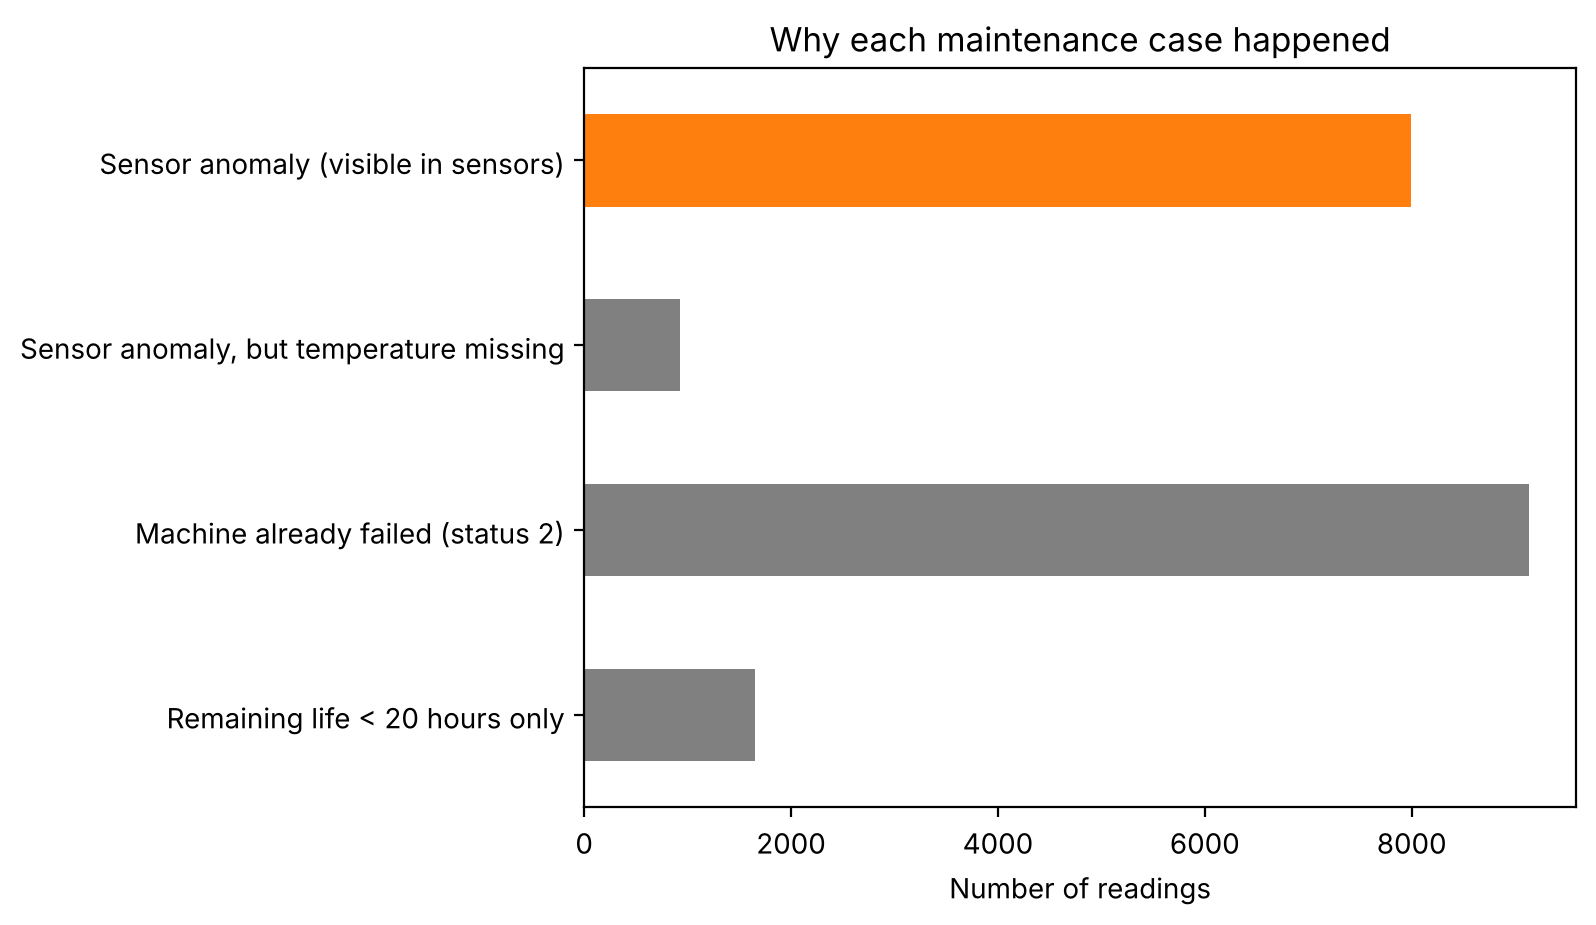

In [24]:
hidden = (df_clean["anomaly_flag"] == 1) & missing & (df_clean["vibration"] <= 80)
reasons = pd.Series({
    "Sensor anomaly (visible in sensors)": ((df_clean["anomaly_flag"] == 1) & ~hidden).sum(),
    "Sensor anomaly, but temperature missing": hidden.sum(),
    "Machine already failed (status 2)": ((df_clean["machine_status"] == 2) & (df_clean["anomaly_flag"] == 0)).sum(),
    "Remaining life < 20 hours only": (target_rule & (df_clean["anomaly_flag"] == 0) & (df_clean["machine_status"] != 2)).sum(),
})
print(reasons, "\n")
print((reasons / reasons.sum() * 100).round(1))

reasons.plot(kind="barh", color=["tab:orange", "grey", "grey", "grey"], title="Why each maintenance case happened")
plt.xlabel("Number of readings")
plt.gca().invert_yaxis()
plt.show()

**What we found:** only **about 41 %** of maintenance cases show up in the sensors. The rest come from machines that had already failed (46 %), from low remaining life (8 %), or from anomalies hidden by a missing temperature (5 %).

### Step 6: do failed machines have different sensor readings?
**Why this table:** if failed machines had unusual readings, the sensors could still help predict failures. We compare the average readings for each machine status.

In [25]:
df_clean.groupby("machine_status")[SENSORS].mean().round(2)

,temperature,vibration,humidity,pressure,energy_consumption
machine_status,,,,,
0,75.13,49.77,54.88,3.0,2.76
1,75.01,50.05,55.01,3.0,2.75
2,75.09,49.97,54.98,3.0,2.74


**What we found:** the averages are almost identical whether a machine is idle, running or failed. **Failures do not show up in the sensors.**

### Which columns can be used to train models?

| Column | Use for training? | Reason |
|---|---|---|
| temperature, vibration, humidity, pressure, energy_consumption | ✅ Yes | Real sensor readings, available before a failure |
| anomaly_flag, downtime_risk | ❌ No | Part of the target's rule (leakage) |
| predicted_remaining_life | ❌ No | Part of the target's rule (leakage) |
| machine_status, failure_type | ❌ No | Only known **after** the machine fails, which is too late for an alert |
| machine_id | ❌ No (as a feature) | No effect (Section 8). Still used to say *which* machine needs maintenance |

The derived columns are still useful: they **explain** how the target is made, which answers the problem statement's question about which features decide `maintenance_required`.

## 7. Sensors vs target
**Why:** to see which sensors are linked to maintenance, and *how* they are linked.

**Why this table (heatmap):** correlation shows how strongly two columns move together, from -1 to +1. 0 means no straight-line link.

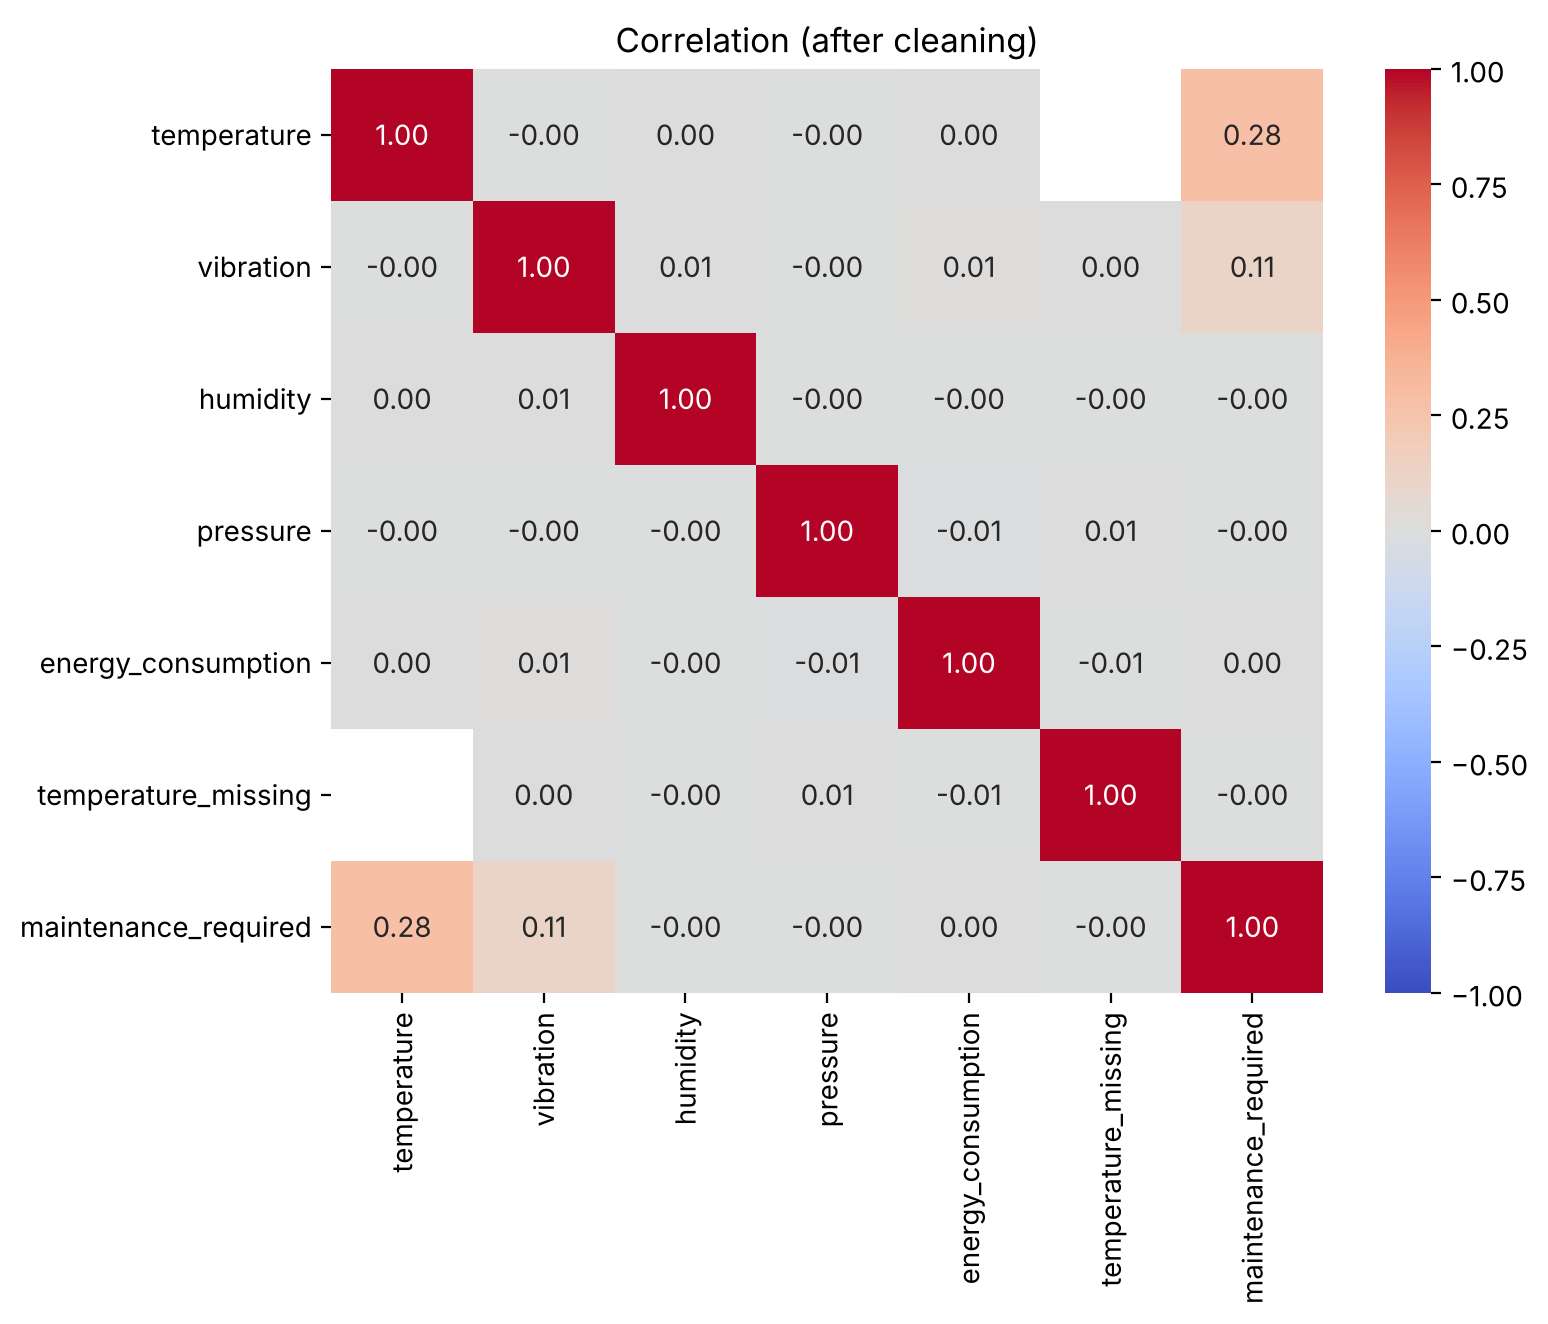

Vibration vs target before cleaning: 0.051
Vibration vs target after cleaning:  0.113


In [26]:
cols = SENSORS + ["temperature_missing", TARGET]
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation (after cleaning)")
plt.show()

print("Vibration vs target before cleaning:", round(df["vibration"].corr(df[TARGET]), 3))
print("Vibration vs target after cleaning: ", round(df_clean["vibration"].corr(df_clean[TARGET]), 3))

Correlation only measures straight-line links, so we also plot the maintenance rate across each sensor's range.

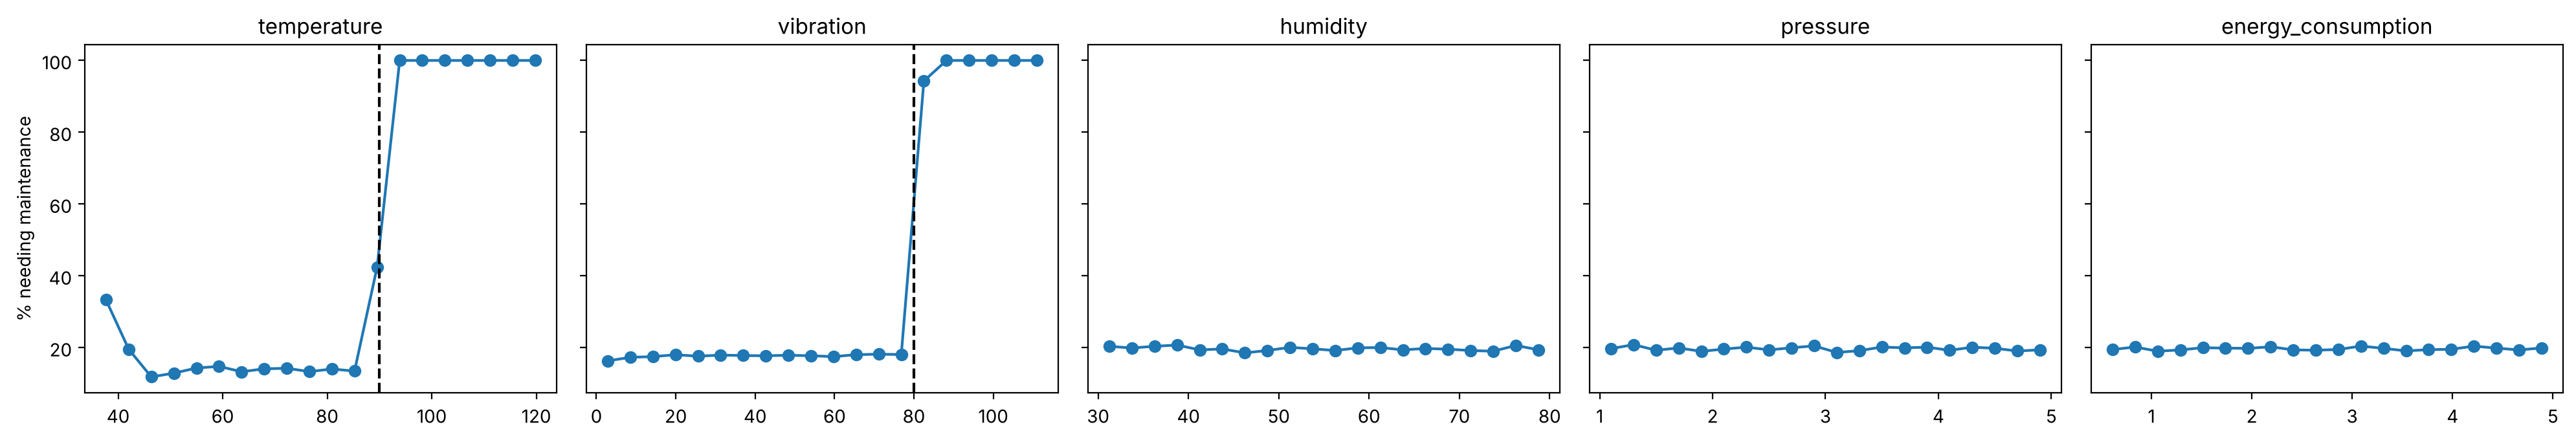

In [27]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharey=True)
for ax, col in zip(axes, SENSORS):
    data = df_clean[[col, TARGET]].dropna()
    rate = data.groupby(pd.cut(data[col], 20), observed=True)[TARGET].mean() * 100
    ax.plot([b.mid for b in rate.index], rate.values, marker="o")
    ax.set_title(col)
axes[0].axvline(90, color="black", linestyle="--")
axes[1].axvline(80, color="black", linestyle="--")
axes[0].set_ylabel("% needing maintenance")
plt.tight_layout()
plt.show()

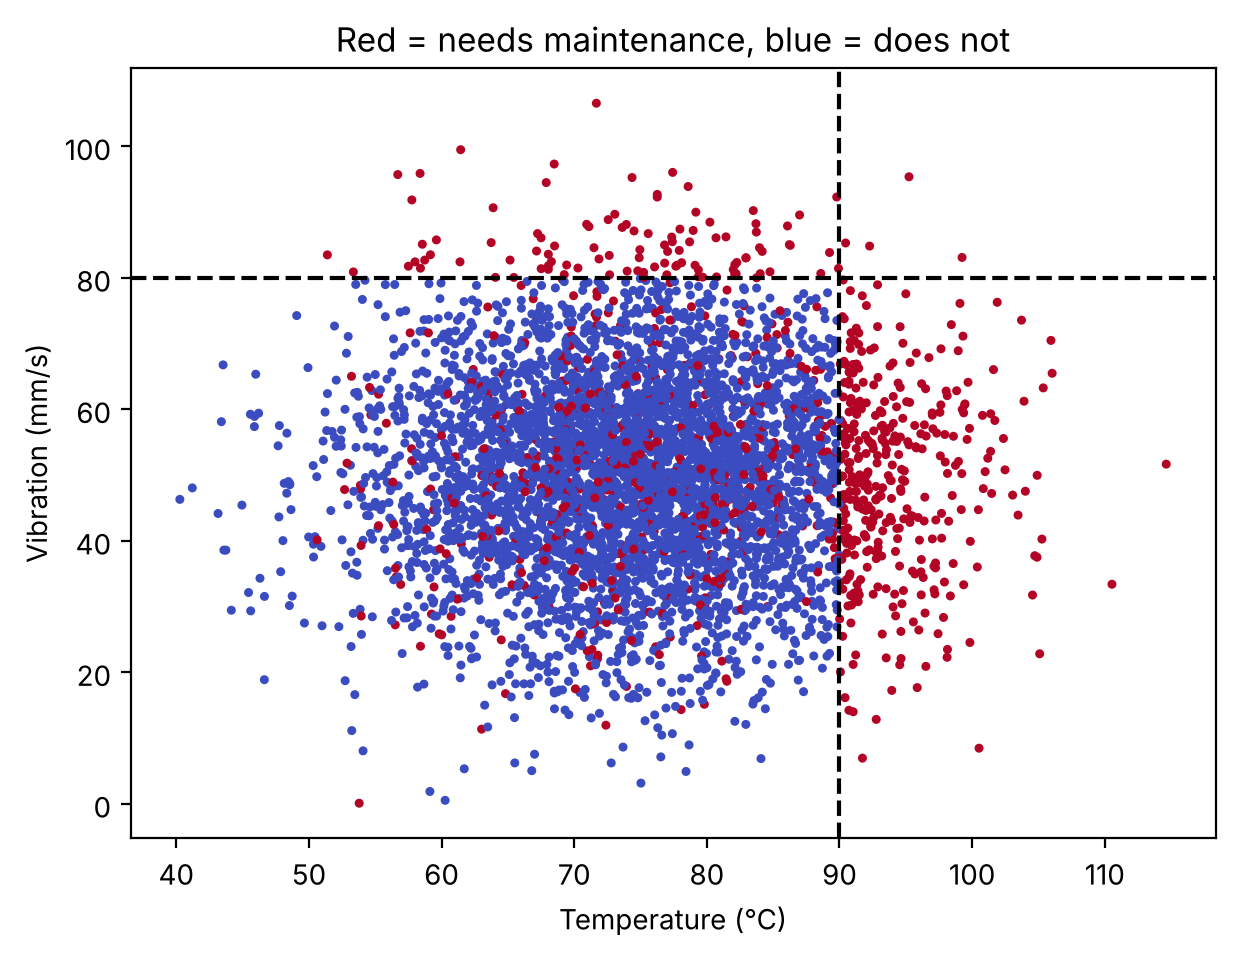

Maintenance rate below both lines: 11.9 %


In [28]:
sample = df_clean.dropna(subset=["temperature"]).sample(5000, random_state=42)
plt.figure(figsize=(7, 5))
plt.scatter(sample["temperature"], sample["vibration"], c=sample[TARGET], cmap="coolwarm", s=5)
plt.axvline(90, color="black", linestyle="--")
plt.axhline(80, color="black", linestyle="--")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration (mm/s)")
plt.title("Red = needs maintenance, blue = does not")
plt.show()

below_both = (df_clean["temperature"] <= 90) & (df_clean["vibration"] <= 80)
print("Maintenance rate below both lines:", round(df_clean.loc[below_both, TARGET].mean() * 100, 1), "%")

**What we found**
- **Temperature** has the strongest link (0.28), followed by **vibration** (0.11). Cleaning helped: vibration's link was only 0.05 before taking the absolute value.
- **Humidity, pressure and energy consumption have no link** to maintenance (about 0).
- The link is a **sudden jump, not a gradual increase.** Above 90 °C or 80 mm/s, 100 % of readings need maintenance. Below both lines, the rate stays flat at about 12 %, and the sensors cannot tell those cases apart.
- *For Task 2:* models that work with cut-off points (such as decision trees) should pick this pattern up easily. A straight-line model (such as logistic regression) may need extra columns like "temperature > 90".

## 8. Machine and time
**Why:** if some machines or times need maintenance more often, those columns would be useful features. We also check whether a machine's past readings help predict its next one.

**Why this chart:** it shows the maintenance rate for each machine, hour, weekday and week. The chi-square p-value tells us whether the differences are real (p < 0.05) or just random (p > 0.05).

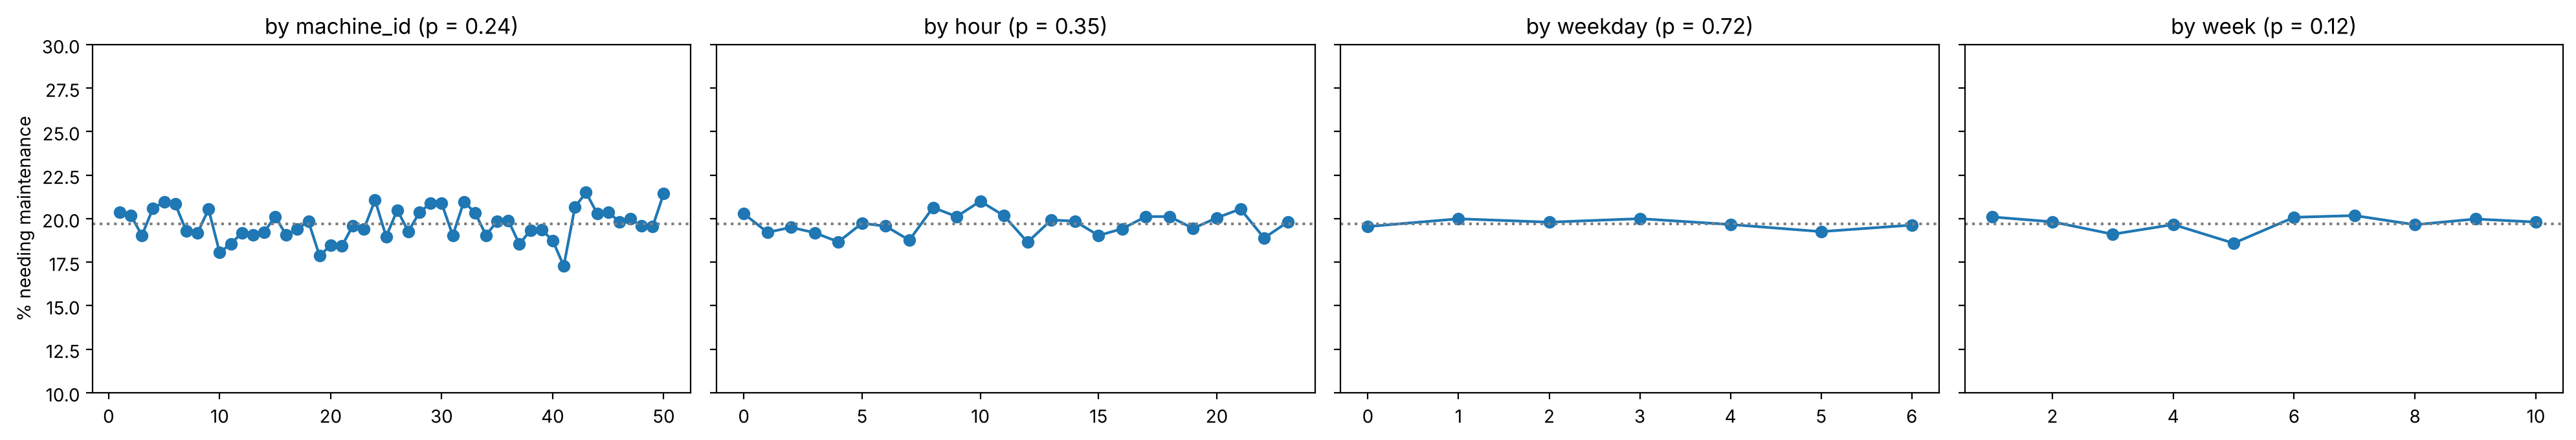

In [29]:
df_clean["hour"] = df_clean["timestamp"].dt.hour
df_clean["weekday"] = df_clean["timestamp"].dt.dayofweek          # 0 = Monday
df_clean["week"] = (df_clean["timestamp"] - df_clean["timestamp"].min()).dt.days // 7 + 1

fig, axes = plt.subplots(1, 4, figsize=(20, 3.5), sharey=True)
for ax, col in zip(axes, ["machine_id", "hour", "weekday", "week"]):
    rate = df_clean.groupby(col)[TARGET].mean() * 100
    p = stats.chi2_contingency(pd.crosstab(df_clean[col], df_clean[TARGET])).pvalue
    ax.plot(rate.index, rate.values, marker="o")
    ax.axhline(df_clean[TARGET].mean() * 100, color="grey", linestyle=":")
    ax.set_title(f"by {col} (p = {p:.2f})")
    ax.set_ylim(10, 30)
axes[0].set_ylabel("% needing maintenance")
plt.tight_layout()
plt.show()

**Why this table:** it measures how similar each reading is to the **same machine's previous reading** (a correlation). If machines slowly wear down, this number would be high.

In [30]:
by_machine = df_clean.sort_values(["machine_id", "timestamp"]).groupby("machine_id")
pd.Series({col: by_machine[col].apply(lambda s: s.autocorr()).mean()
           for col in SENSORS + ["predicted_remaining_life", TARGET]},
          name="link to the machine's previous reading").round(3).to_frame()

,link to the machine's previous reading
temperature,-0.003
vibration,0.002
humidity,-0.000
pressure,0.003
energy_consumption,0.003
predicted_remaining_life,0.002
maintenance_required,0.006


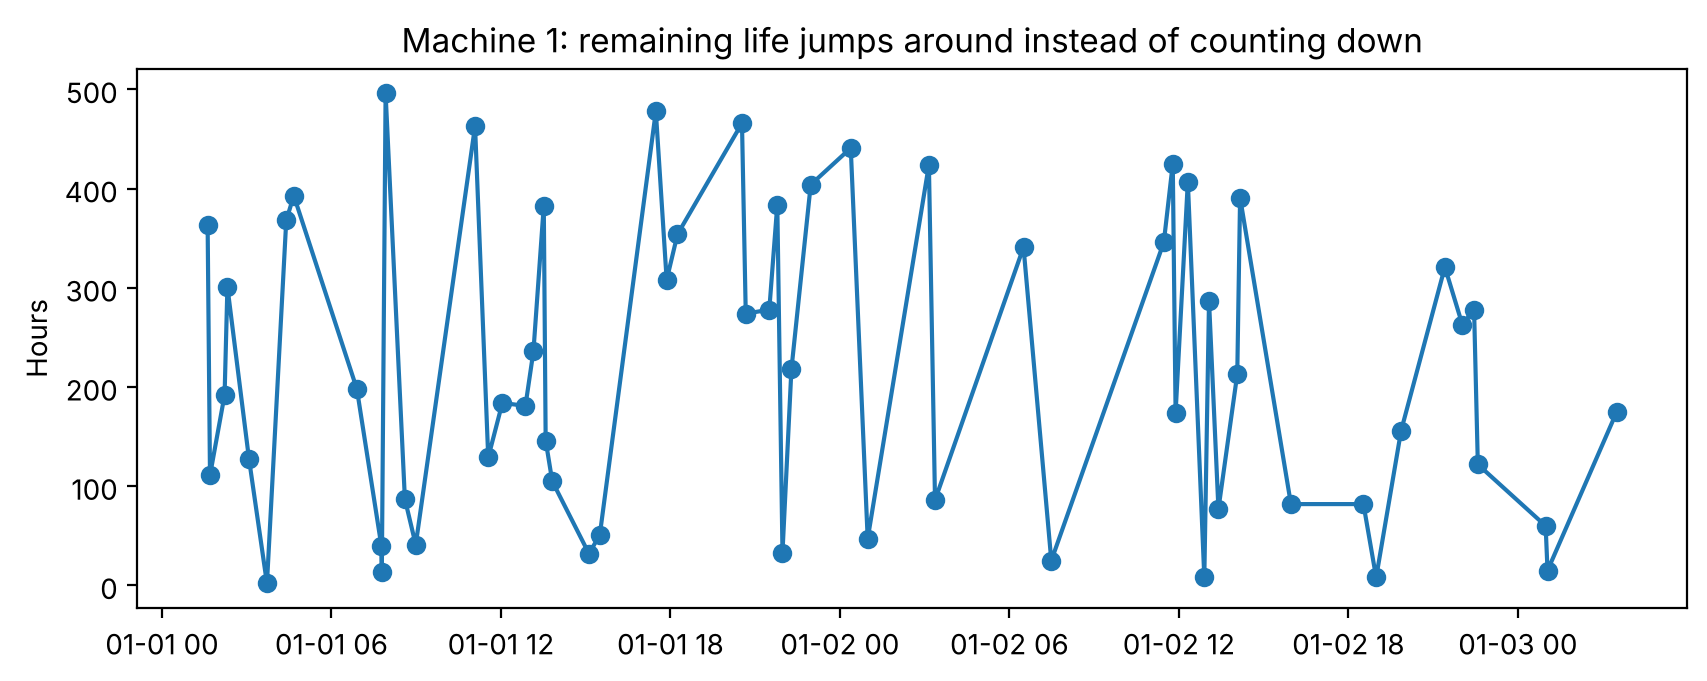

In [31]:
machine_1 = df_clean[df_clean["machine_id"] == 1].head(60)
plt.figure(figsize=(10, 3.5))
plt.plot(machine_1["timestamp"], machine_1["predicted_remaining_life"], marker="o")
plt.title("Machine 1: remaining life jumps around instead of counting down")
plt.ylabel("Hours")
plt.show()

**Why this table:** Task 2 will probably train on older data and test on newer data. We check that both parts have a similar maintenance rate.

In [32]:
split = int(len(df_clean) * 0.8)
print("Maintenance rate, first 80 % of time:", round(df_clean[TARGET].iloc[:split].mean() * 100, 1), "%")
print("Maintenance rate, last 20 % of time: ", round(df_clean[TARGET].iloc[split:].mean() * 100, 1), "%")

Maintenance rate, first 80 % of time: 19.6 %
Maintenance rate, last 20 % of time:  19.9 %


**What we found**
- All p-values are above 0.05 (machine 0.24, hour 0.35, weekday 0.72, week 0.12). **No machine, hour, weekday or week needs maintenance more often than the others.**
- A reading is **not linked to the same machine's previous reading** (about 0), and remaining life does not count down. So a machine's history does not help, and features like "average of the last 5 readings" would not add anything.
- This means alerts can only be based on **each machine's current reading**.
- *For Task 2:* splitting by time (older data for training, newer data for testing) is realistic, and both parts have a similar maintenance rate (19.6 % vs 19.9 %).

## 9. Decisions

| Decision | Reason | Section |
|---|---|---|
| Use the absolute value of vibration | Negative values are real values with a wrong minus sign | 5.1 |
| Fill missing temperature with the median and add `temperature_missing` | Missing at random; mean ≈ median; no other sensor can predict temperature; missing rows are riskier | 5.2 |
| Keep outliers | High temperatures all need maintenance. They are the signal, not errors | 5.3 |
| Do not train on the derived columns | They make up the target's rule (leakage), or are only known after a failure | 6 |
| Do not use machine_id or time as features | No difference between machines or times | 8 |
| Focus on recall in Task 2 | Missing a breakdown is worse than a false alarm | 2 |

## 10. Summary
1. **The data is clean overall:** no duplicates, correct types, and one reading per minute from 50 machines over about 10 weeks. The data looks simulated.
2. **Two problems fixed:** missing temperature (14 %) is filled with the median plus a "missing" column, and negative vibration (6.7 %) is turned positive.
3. **The target follows a simple rule:** anomaly OR machine failed OR remaining life < 20 hours. These columns are not used for training, because they give away the answer.
4. **Only temperature (> 90 °C) and vibration (> 80 mm/s) matter.** Humidity, pressure, energy, machine and time do not.
5. **The sensors only explain about 41 % of maintenance cases.** Failed machines and low remaining life leave no sign in the sensors. To catch more breakdowns early, the company would need more or better sensors.

**For Task 2 (pipeline):** load the data with SQLite, take the absolute value of vibration, add `temperature_missing`, fill temperature with the training-data median, train on sensor columns only, split by time, and focus on recall.